In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv('brca.csv')
df.head()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


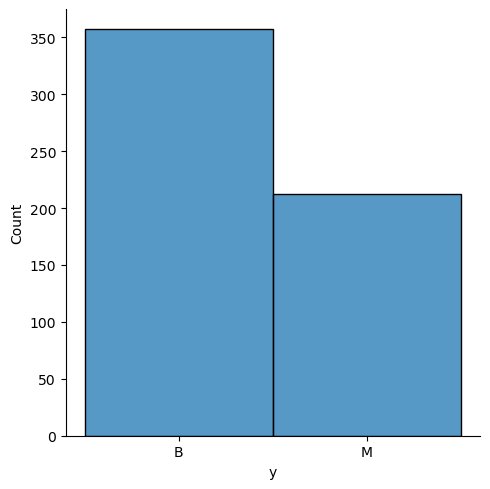

In [3]:
sns.displot(df['y'])
plt.show()

In [4]:
 def b_m(x):
     if x == 'B':
         return 1
     else:
         return 0

In [5]:
df['y'] = df['y'].apply(b_m)

In [6]:
df.corr()['y'].sort_values()

Unnamed: 0            -0.837435
x.concave_pts_worst   -0.793566
x.perimeter_worst     -0.782914
x.concave_pts_mean    -0.776614
x.radius_worst        -0.776454
x.perimeter_mean      -0.742636
x.area_worst          -0.733825
x.radius_mean         -0.730029
x.area_mean           -0.708984
x.concavity_mean      -0.696360
x.concavity_worst     -0.659610
x.compactness_mean    -0.596534
x.compactness_worst   -0.590998
x.radius_se           -0.567134
x.perimeter_se        -0.556141
x.area_se             -0.548236
x.texture_worst       -0.456903
x.smoothness_worst    -0.421465
x.symmetry_worst      -0.416294
x.texture_mean        -0.415185
x.concave_pts_se      -0.408042
x.smoothness_mean     -0.358560
x.symmetry_mean       -0.330499
x.fractal_dim_worst   -0.323872
x.compactness_se      -0.292999
x.concavity_se        -0.253730
x.fractal_dim_se      -0.077972
x.symmetry_se          0.006522
x.texture_se           0.008303
x.fractal_dim_mean     0.012838
x.smoothness_se        0.067016
y       

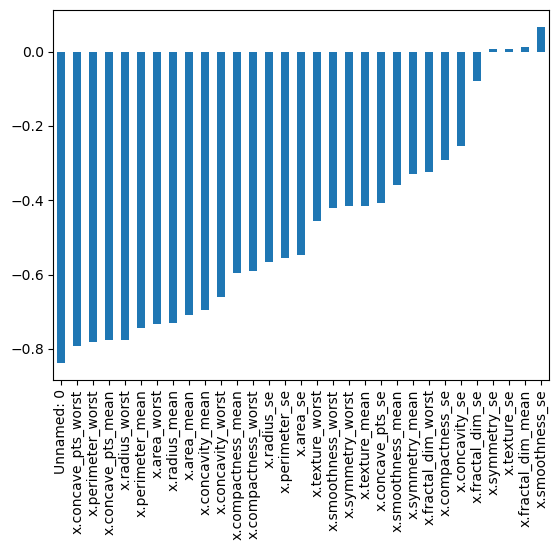

In [7]:
df.corr()['y'][:-1].sort_values().plot(kind='bar')
plt.show()

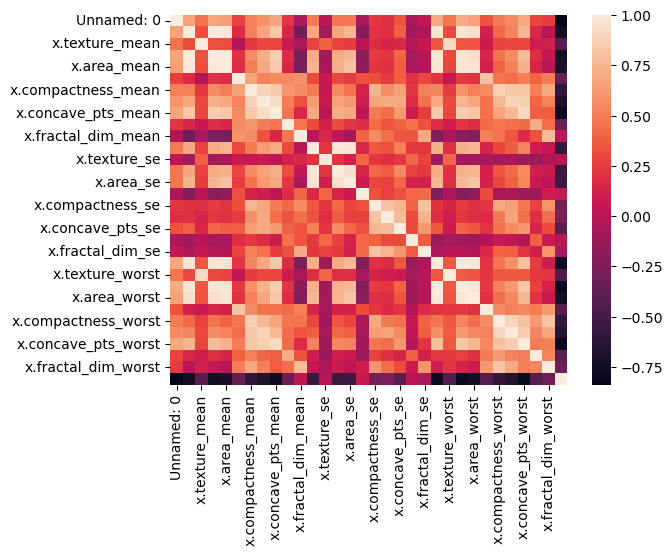

In [8]:
sns.heatmap(df.corr())
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [10]:
X = df.drop(['Unnamed: 0','y'], axis=1).values
y = df['y'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [11]:
scaler = MinMaxScaler()

In [12]:
X_train = scaler.fit_transform(X_train)

In [13]:
X_test = scaler.transform(X_test)

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [15]:
model = Sequential()

model.add(Dense(30, activation='relu'))
model.add(Dense(15, activation='relu'))

#BINARY CLASSIFICATION / AS WE NEED 1 OR 0
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam')

In [16]:
model.fit(x=X_train, y=y_train, epochs=600, validation_data=(X_test, y_test))

Epoch 1/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.6788 - val_loss: 0.6326
Epoch 2/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6330 - val_loss: 0.6013
Epoch 3/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5946 - val_loss: 0.5572
Epoch 4/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5512 - val_loss: 0.5164
Epoch 5/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5085 - val_loss: 0.4718
Epoch 6/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4688 - val_loss: 0.4410
Epoch 7/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4313 - val_loss: 0.4079
Epoch 8/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3933 - val_loss: 0.3714
Epoch 9/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3564 - val_loss: 0.3408
Epoch 10/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3195 - val_loss: 0.3110
Epoch 11/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2889 - val_loss: 0.2887
Epoch 12/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

In [17]:
losses = pd.DataFrame(model.history.history)

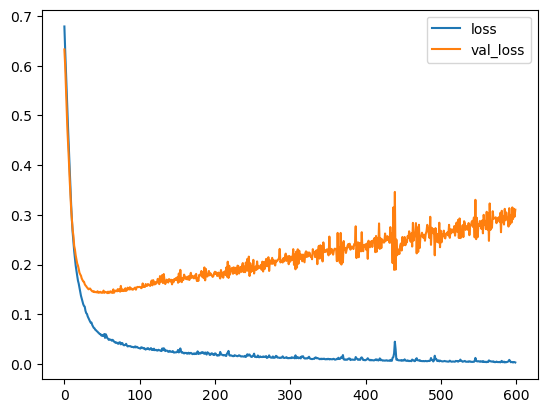

In [20]:
losses.plot()
plt.show()

In [21]:
model = Sequential()

model.add(Dense(30, activation='relu'))
model.add(Dense(15, activation='relu'))

#BINARY CLASSIFICATION / AS WE NEED 1 OR 0
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam')

In [23]:
from tensorflow.keras.callbacks import EarlyStopping

In [24]:
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25)

In [25]:
model.fit(x=X_train, y=y_train, epochs=600, validation_data=(X_test, y_test), callbacks=[early_stop])

Epoch 1/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.7083 - val_loss: 0.6789
Epoch 2/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6500 - val_loss: 0.6378
Epoch 3/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6021 - val_loss: 0.6055
Epoch 4/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.5602 - val_loss: 0.5561
Epoch 5/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5160 - val_loss: 0.5143
Epoch 6/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4746 - val_loss: 0.4722
Epoch 7/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4356 - val_loss: 0.4379
Epoch 8/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3969 - val_loss: 0.3968
Epoch 9/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3620 - val_loss: 0.3763
Epoch 10/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3331 - val_loss: 0.3416
Epoch 11/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3073 - val_loss: 0.3197
Epoch 12/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

In [26]:
model_loss = pd.DataFrame(model.history.history)

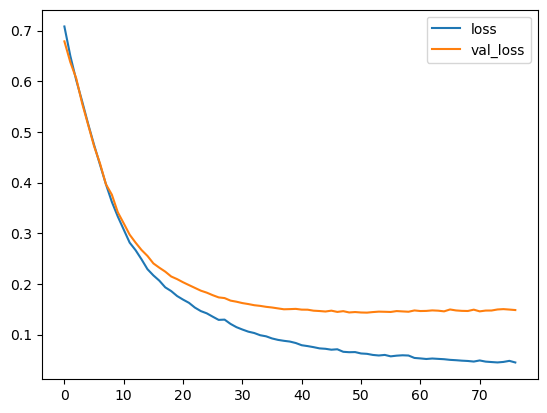

In [27]:
model_loss.plot()
plt.show()

In [28]:
from tensorflow.keras.layers import Dropout

In [29]:
model = Sequential()

model.add(Dense(30, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(15, activation='relu'))
model.add(Dropout(0.5))

#BINARY CLASSIFICATION / AS WE NEED 1 OR 0
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam')

In [30]:
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25)

In [31]:
model.fit(x=X_train, y=y_train, epochs=600, validation_data=(X_test, y_test), callbacks=[early_stop])

Epoch 1/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.7001 - val_loss: 0.6791
Epoch 2/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.6599 - val_loss: 0.6568
Epoch 3/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6589 - val_loss: 0.6266
Epoch 4/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6335 - val_loss: 0.6008
Epoch 5/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6325 - val_loss: 0.5741
Epoch 6/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5944 - val_loss: 0.5454
Epoch 7/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.5644 - val_loss: 0.5168
Epoch 8/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.5728 - val_loss: 0.4937
Epoch 9/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5371 - val_loss: 0.4694
Epoch 10/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5126 - val_loss: 0.4452
Epoch 11/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4828 - val_loss: 0.4201
Epoch 12/600
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 

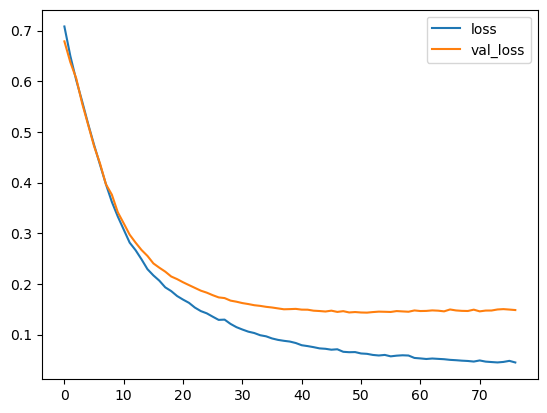

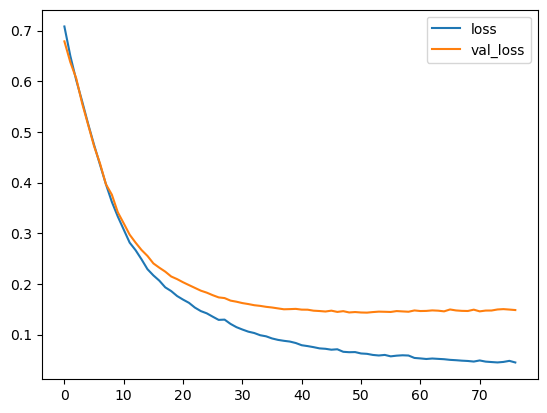

In [33]:
model_loss_2 = pd.DataFrame(model.history.history)
model_loss.plot()
plt.show()

In [35]:
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [38]:
pred

array([[9.8683989e-01],
       [6.6642795e-04],
       [9.9418133e-01],
       [9.9266613e-01],
       [9.9980623e-01],
       [9.9605292e-01],
       [9.9982232e-01],
       [7.6574320e-01],
       [9.9517202e-01],
       [9.9948978e-01],
       [9.9532747e-01],
       [9.9937147e-01],
       [9.9994004e-01],
       [9.9991131e-01],
       [9.9934268e-01],
       [3.2058823e-01],
       [9.9383730e-01],
       [4.4699219e-01],
       [9.9893659e-01],
       [3.5360180e-02],
       [9.9996883e-01],
       [3.4059005e-04],
       [9.9998271e-01],
       [6.6317909e-07],
       [9.9998802e-01],
       [1.9864734e-05],
       [9.9903005e-01],
       [9.4483477e-01],
       [9.9972284e-01],
       [2.1008649e-05],
       [9.9969971e-01],
       [9.9736917e-01],
       [3.9806404e-05],
       [9.9997115e-01],
       [6.7973417e-01],
       [8.0121785e-01],
       [9.4471121e-01],
       [9.8677546e-01],
       [9.9603534e-01],
       [9.9448860e-01],
       [9.9892032e-01],
       [9.999944

In [36]:
from sklearn.metrics import classification_report, confusion_matrix

In [39]:
pred.shape

(171, 1)

In [43]:
pred_classes = (pred > 0.5).astype("int").flatten()
pred_classes

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1])

In [41]:
y_test

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1], dtype=int64)

In [44]:
pred_classes.shape

(171,)

In [46]:
print(classification_report(y_test, pred_classes))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93        52
           1       0.97      0.97      0.97       119

    accuracy                           0.96       171
   macro avg       0.95      0.95      0.95       171
weighted avg       0.96      0.96      0.96       171



In [47]:
print(confusion_matrix(y_test, pred_classes))

[[ 48   4]
 [  3 116]]
